# UCI student performance — exploration

This notebook presents the Week 8 data review. Figures are computed by functions in the `data_science` package, not reimplemented here. No classifier or regressor is trained.


## Dataset

Source: Cortez, P. and Silva, A. (2008). *Using Data Mining to Predict Secondary School Student Performance*. In A. Brito and J. Teixeira (Eds.), Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008), Porto, Portugal.

UCI Machine Learning Repository, Student Performance, dataset 320. License: CC BY 4.0.  
https://archive.ics.uci.edu/dataset/320/student+performance

The mathematics and Portuguese files are read together. `subject` is `mat` or `por`. The same student can appear in both files. `student_key` hashes the shared demographic columns, and the common-student count is the size of that intersection. The next cell prints row counts, the common-student count, and the number of missing cells.


In [1]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "data_science").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data_science.config import PASS_GRADE_100, PASS_THRESHOLD_20
from data_science.eda import (
    G3_BINS,
    build_summary,
    g3_zero_by_subject,
    grade_points,
    numeric_correlation_matrix,
)
from data_science.features import (
    ABSENCE_BINS,
    add_derived_columns,
    build_dataset,
    build_preprocessor,
    feature_columns,
)
from data_science.load import load_students

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
    }
)
SUBJECT_COLORS = {"mat": "#1f77b4", "por": "#ff7f0e"}

students = load_students()
summary = build_summary(students)

print("rows_total", summary["row_counts"]["total"])
print("rows_mat", summary["row_counts"]["mat"])
print("rows_por", summary["row_counts"]["por"])
print("common_student_count", summary["common_student_count"])
print("missing_value_count", summary["missing_value_count"])


ortak_ogrenci_sayisi=366
rows_total 1044
rows_mat 395
rows_por 649
common_student_count 366
missing_value_count 0


## Target

A course row is at risk when the final grade on the 20-point scale is below the pass threshold: `at_risk = 1` if `G3 < PASS_THRESHOLD_20`. Five times that threshold is the same rule as the school pass grade on the 100-point scale (`PASS_GRADE`). A grade equal to the threshold is a pass. The next cell prints the threshold, its 100-point equivalent, and the pass rate by subject; the chart shows the same rates.


pass_threshold_20 10
equivalent_pass_grade_100 50
pass_rate_mat 0.6708860759493671
pass_rate_por 0.8459167950693375


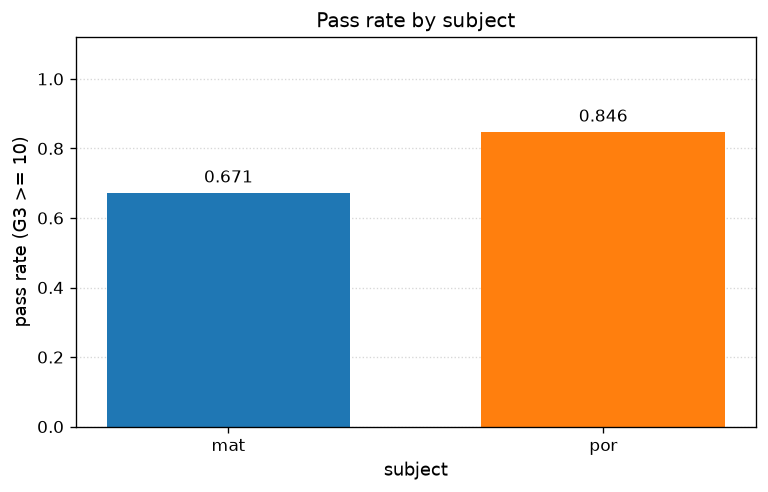

In [2]:
print("pass_threshold_20", PASS_THRESHOLD_20)
print("equivalent_pass_grade_100", PASS_GRADE_100)
for subject, rate in summary["pass_rate_by_subject"].items():
    print(f"pass_rate_{subject}", rate)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for subject, rate in summary["pass_rate_by_subject"].items():
    ax.bar(subject, rate, color=SUBJECT_COLORS[subject], width=0.65)
    ax.text(subject, rate + 0.02, f"{rate:.3f}", ha="center", va="bottom")
ax.set_ylim(0, 1.12)
ax.set_xlabel("subject")
ax.set_ylabel(f"pass rate (G3 >= {PASS_THRESHOLD_20})")
ax.set_title("Pass rate by subject")
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", alpha=0.5)
fig.tight_layout()
plt.show()


## G3 distribution

The histogram separates the final grade by course. Rows whose final grade is zero are kept, and `g3_zero` flags them. The cell prints how many zero grades there are, overall and by subject.


g3_zero_count 53
g3_zero_mat 38
g3_zero_por 15


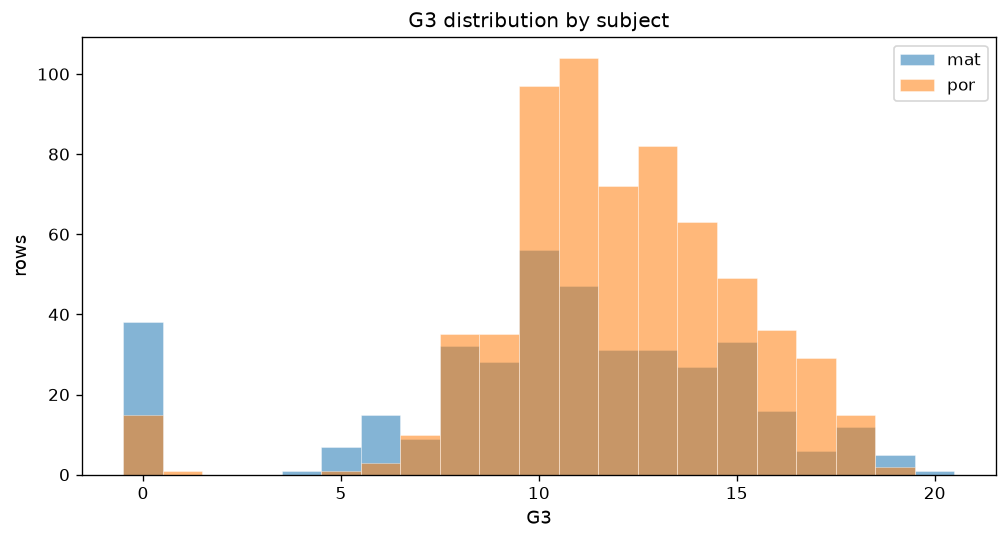

In [3]:
featured = add_derived_columns(students)
zero_by_subject = g3_zero_by_subject(students)
print("g3_zero_count", int(featured["g3_zero"].sum()))
for subject, count in zero_by_subject.items():
    print(f"g3_zero_{subject}", int(count))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
bins = G3_BINS
for subject in ("mat", "por"):
    ax.hist(
        students.loc[students["subject"] == subject, "G3"],
        bins=bins,
        alpha=0.55,
        label=subject,
        color=SUBJECT_COLORS[subject],
        edgecolor="white",
        linewidth=0.4,
    )
ax.set_xlabel("G3")
ax.set_ylabel("rows")
ax.set_title("G3 distribution by subject")
ax.legend()
fig.tight_layout()
plt.show()


## Correlations

Pearson correlations between the numeric columns and G3 are ranked by absolute value. The horizontal bar keeps the sign of the ten strongest relationships. The heatmap is the correlation of the numeric columns with each other, including the period grades and the final grade.


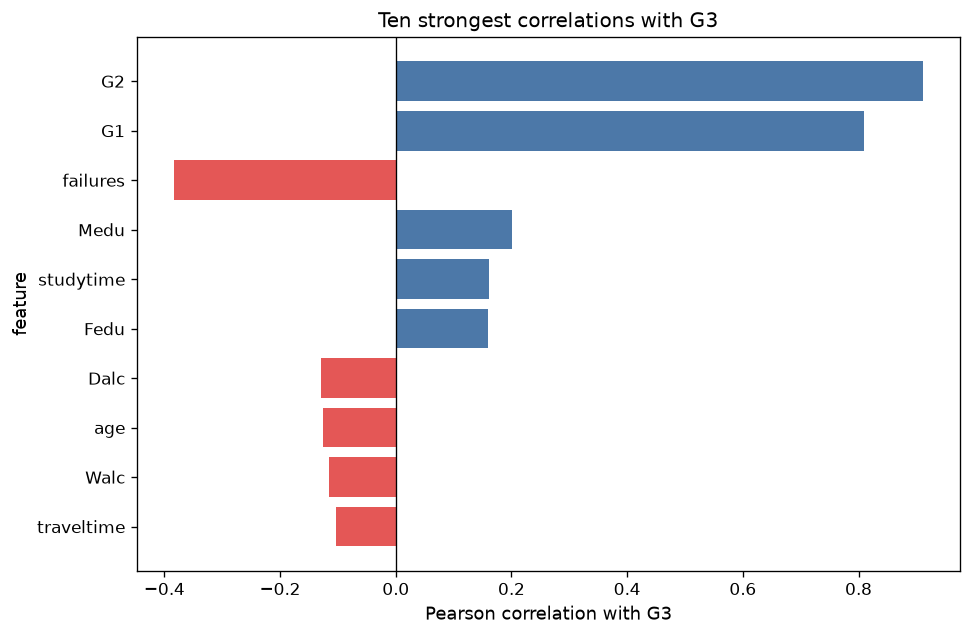

G2 0.9107431630583628
G1 0.8091417205401191
failures -0.3831452797182739
Medu 0.2014716902409074
studytime 0.16162893520293828
Fedu 0.15979604944494527
Dalc -0.12964212480071255
age -0.12528243256718005
Walc -0.11574000357145996
traveltime -0.10262711753091319


In [4]:
top = pd.DataFrame(summary["top_abs_correlation_with_g3"])
ordered = top.iloc[::-1]
colors = ["#4c78a8" if value >= 0 else "#e45756" for value in ordered["correlation"]]

fig, ax = plt.subplots(figsize=(8.2, 5.4))
ax.barh(ordered["feature"], ordered["correlation"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Pearson correlation with G3")
ax.set_ylabel("feature")
ax.set_title("Ten strongest correlations with G3")
fig.tight_layout()
plt.show()

for row in top.itertuples(index=False):
    print(row.feature, row.correlation)


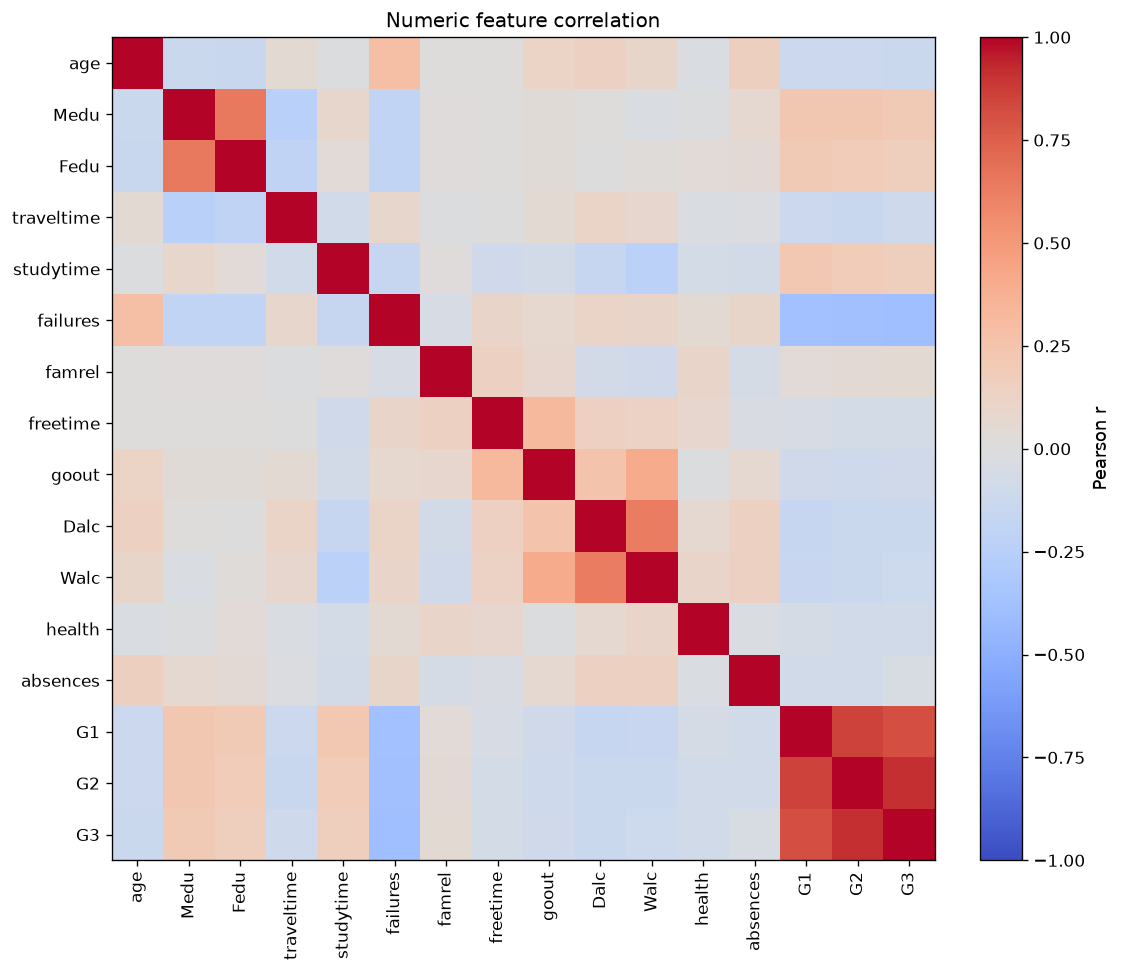

In [5]:
matrix = numeric_correlation_matrix(students)
labels = list(matrix.columns)
fig, ax = plt.subplots(figsize=(10.5, 8.2))
image = ax.imshow(matrix.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels)
ax.set_title("Numeric feature correlation")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04).set_label("Pearson r")
fig.tight_layout()
plt.show()


## Leakage

Period grades lie close to the final grade. The plots are G1 against G3 and G2 against G3. EARLY is the start-of-term feature set, so it leaves both period grades out. MIDTERM keeps only the first-period grade. G3 is in neither set, because it defines the label. The cell prints the two correlations and checks those exclusions against the package feature lists.


g1_g3_correlation 0.8091417205401191
g2_g3_correlation 0.9107431630583628
early_has_G1 False
early_has_G2 False
early_has_G3 False
midterm_has_G1 True
midterm_has_G2 False
midterm_has_G3 False


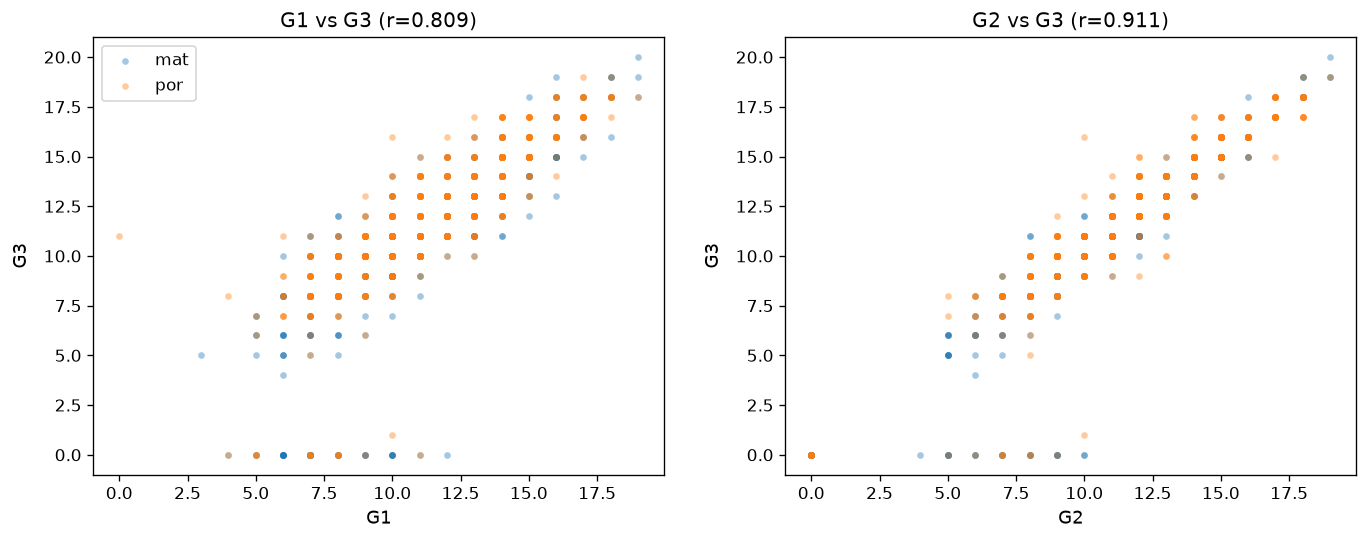

In [6]:
print("g1_g3_correlation", summary["g1_g3_correlation"])
print("g2_g3_correlation", summary["g2_g3_correlation"])
early_columns = feature_columns("early")
midterm_columns = feature_columns("midterm")
print("early_has_G1", "G1" in early_columns)
print("early_has_G2", "G2" in early_columns)
print("early_has_G3", "G3" in early_columns)
print("midterm_has_G1", "G1" in midterm_columns)
print("midterm_has_G2", "G2" in midterm_columns)
print("midterm_has_G3", "G3" in midterm_columns)

points = grade_points(students)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
pairs = (
    ("G1", "G3", summary["g1_g3_correlation"]),
    ("G2", "G3", summary["g2_g3_correlation"]),
)
for ax, (left, right, correlation) in zip(axes, pairs):
    for subject in ("mat", "por"):
        part = points.loc[points["subject"] == subject]
        ax.scatter(
            part[left],
            part[right],
            s=16,
            alpha=0.4,
            c=SUBJECT_COLORS[subject],
            label=subject,
            linewidths=0,
        )
    ax.set_xlabel(left)
    ax.set_ylabel(right, labelpad=8)
    ax.set_title(f"{left} vs {right} (r={correlation:.3f})")
axes[0].legend()
fig.tight_layout(w_pad=2.4)
plt.show()


## Absences

`absence_bucket` is the package's binning of the absence count. For each bin the cell reports the number of rows and the pass rate. The same table is built again after rows with a zero final grade are removed. Pearson and Spearman correlations between `absences` and G3 are printed as four numbers: zeros included and zeros excluded.


absence_buckets_all


 absence_bucket absence_bucket_label  n_rows  pass_rate
              0                    0     359   0.766017
              1                  1-5     368   0.834239
              2                 6-10     202   0.787129
              3                11-20      92   0.663043
              4                  21+      23   0.521739
absence_buckets_excl_g3_zero
 absence_bucket absence_bucket_label  n_rows  pass_rate
              0                    0     306   0.898693
              1                  1-5     368   0.834239
              2                 6-10     202   0.787129
              3                11-20      92   0.663043
              4                  21+      23   0.521739
pearson_all -0.04567057698837366
spearman_all -0.10897236400308523
pearson_excl_g3_zero -0.2180303324076406
spearman_excl_g3_zero -0.23847017701812487


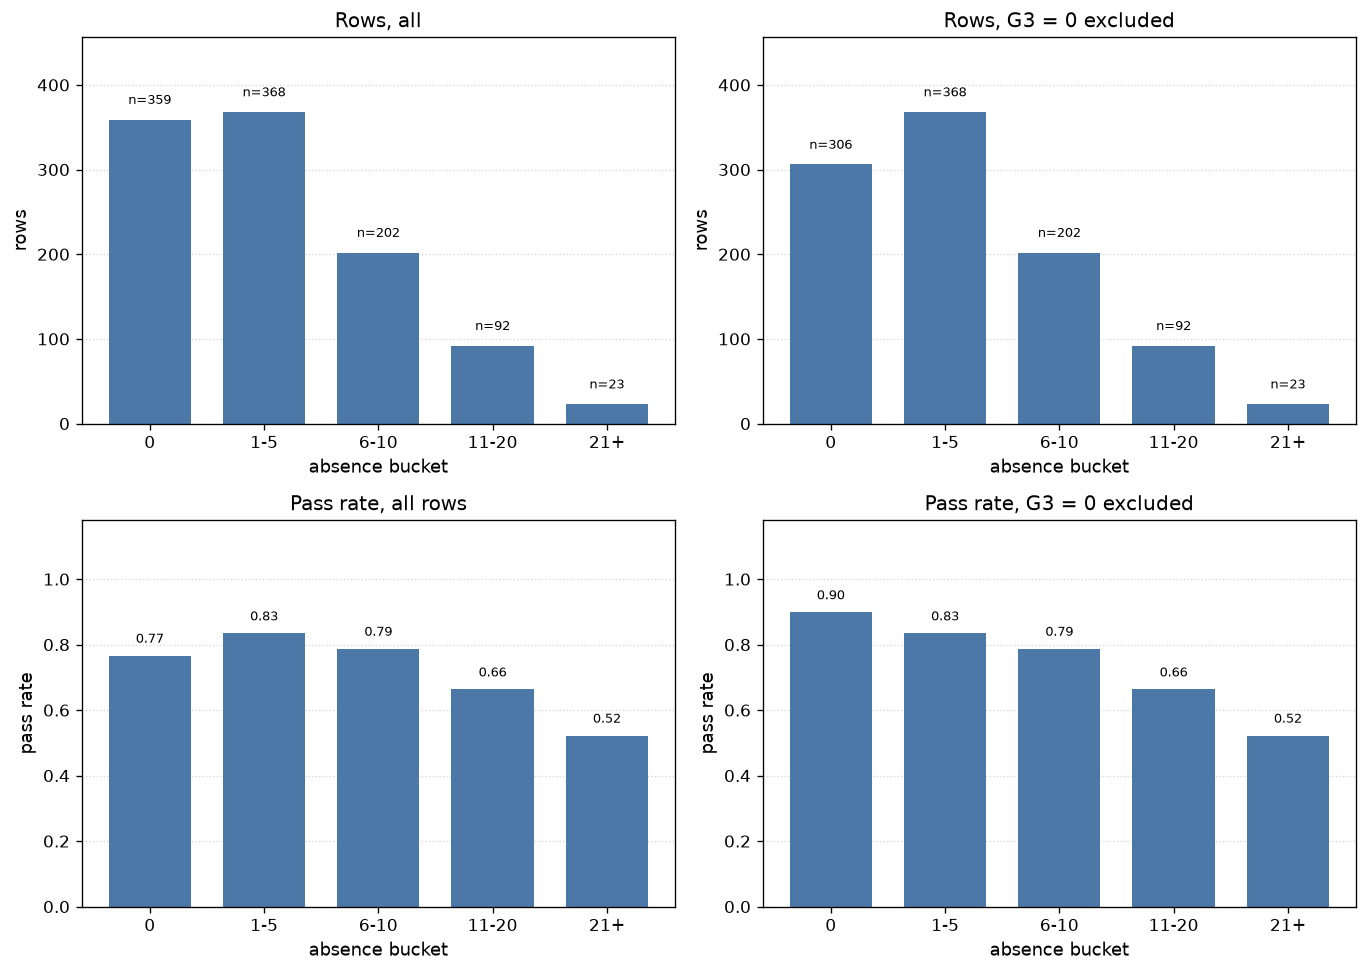

In [7]:
from data_science.absence import absence_grade_corr, absence_pass_table, bucket_labels


absence_table_all = absence_pass_table(featured)
absence_table_excl_g3_zero = absence_pass_table(featured.loc[featured["g3_zero"] == 0])
pearson_all, spearman_all = absence_grade_corr(featured)
pearson_excl, spearman_excl = absence_grade_corr(featured.loc[featured["g3_zero"] == 0])

print("absence_buckets_all")
print(absence_table_all.to_string(index=False, float_format="{:.6f}".format))
print("absence_buckets_excl_g3_zero")
print(absence_table_excl_g3_zero.to_string(index=False, float_format="{:.6f}".format))
print("pearson_all", pearson_all)
print("spearman_all", spearman_all)
print("pearson_excl_g3_zero", pearson_excl)
print("spearman_excl_g3_zero", spearman_excl)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))
panels = (
    (axes[0, 0], absence_table_all, "n_rows", "Rows, all", "rows", None),
    (axes[0, 1], absence_table_excl_g3_zero, "n_rows", "Rows, G3 = 0 excluded", "rows", None),
    (axes[1, 0], absence_table_all, "pass_rate", "Pass rate, all rows", "pass rate", (0, 1.18)),
    (
        axes[1, 1],
        absence_table_excl_g3_zero,
        "pass_rate",
        "Pass rate, G3 = 0 excluded",
        "pass rate",
        (0, 1.18),
    ),
)
for ax, table, column, title, ylabel, ylim in panels:
    heights = table[column].to_numpy(dtype=float)
    ax.bar(table["absence_bucket_label"], heights, color="#4c78a8", width=0.72)
    ax.set_xlabel("absence bucket")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    if ylim is not None:
        ax.set_ylim(*ylim)
    finite = heights[np.isfinite(heights)]
    headroom = 0.03 if column == "pass_rate" else max(float(finite.max()) * 0.04, 1) if len(finite) else 1
    if ylim is None and len(finite):
        ax.set_ylim(0, float(finite.max()) + headroom * 6)
    for label, height, n_rows in zip(table["absence_bucket_label"], heights, table["n_rows"]):
        if not np.isfinite(height):
            continue
        text = f"n={int(n_rows)}" if column == "n_rows" else f"{height:.2f}"
        ax.text(label, height + headroom, text, ha="center", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()


## Feature sets

Column lists are read from the package. The preprocessor is fit in this notebook only to measure how many columns it emits. That fit is not a model. The preprocessor returned by the package is unfitted; fitting belongs inside cross-validation in Week 9.


In [8]:
early_columns = feature_columns("early")
midterm_columns = feature_columns("midterm")
print("EARLY", len(early_columns))
for column in early_columns:
    print(column)
print("MIDTERM", len(midterm_columns))
for column in midterm_columns:
    print(column)

early = build_dataset(students, "early")
midterm = build_dataset(students, "midterm")
# Width only. The package returns the preprocessor unfitted; this is not a model.
early_width = build_preprocessor("early").fit_transform(early[early_columns]).shape
midterm_width = build_preprocessor("midterm").fit_transform(midterm[midterm_columns]).shape
print("early_preprocessor_shape", tuple(int(value) for value in early_width))
print("midterm_preprocessor_shape", tuple(int(value) for value in midterm_width))


EARLY 37
school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
subject
parent_edu_max
alcohol_total
support_any
has_failures
absences_log1p
absence_bucket
MIDTERM 38
school
sex
age
address
famsize
Pstatus
Medu
Fedu
Mjob
Fjob
reason
guardian
traveltime
studytime
failures
schoolsup
famsup
paid
activities
nursery
higher
internet
romantic
famrel
freetime
goout
Dalc
Walc
health
absences
subject
parent_edu_max
alcohol_total
support_any
has_failures
absences_log1p
absence_bucket
G1
early_preprocessor_shape (1044, 51)
midterm_preprocessor_shape (1044, 52)


## Conclusions

The five sentences below are built from numbers computed above.


In [9]:
rates = summary["pass_rate_by_subject"]
higher_subject = max(rates, key=rates.get)
lower_subject = min(rates, key=rates.get)
strongest = summary["top_abs_correlation_with_g3"][0]
second = summary["top_abs_correlation_with_g3"][1]
early_columns = feature_columns("early")
midterm_columns = feature_columns("midterm")
kept = absence_table_all.dropna(subset=["pass_rate"])
dropped = absence_table_excl_g3_zero.dropna(subset=["pass_rate"])
lowest = kept.loc[kept["pass_rate"].idxmin()]
highest = kept.loc[kept["pass_rate"].idxmax()]
lowest_ex = dropped.loc[dropped["pass_rate"].idxmin()]
highest_ex = dropped.loc[dropped["pass_rate"].idxmax()]

print(
    f"1. Rows: {summary['row_counts']['total']} "
    f"(mat {summary['row_counts']['mat']}, por {summary['row_counts']['por']}). "
    f"Common students: {summary['common_student_count']}. "
    f"Missing cells: {summary['missing_value_count']}."
)
print(
    f"2. At G3 >= {PASS_THRESHOLD_20} "
    f"(100-point pass grade {PASS_GRADE_100}), "
    f"pass rate is {rates[higher_subject]:.4f} in {higher_subject} and "
    f"{rates[lower_subject]:.4f} in {lower_subject}."
)
print(
    f"3. Strongest Pearson link with G3 is {strongest['feature']} "
    f"({strongest['correlation']:.4f}), then {second['feature']} "
    f"({second['correlation']:.4f}). "
    f"G1-G3 is {summary['g1_g3_correlation']:.4f} and "
    f"G2-G3 is {summary['g2_g3_correlation']:.4f}. "
    f"EARLY contains G1={'G1' in early_columns}, G2={'G2' in early_columns}; "
    f"MIDTERM contains G1={'G1' in midterm_columns}, G2={'G2' in midterm_columns}; "
    f"G3 is in a feature set={'G3' in early_columns or 'G3' in midterm_columns}."
)
print(
    f"4. G3=0 rows: {int(featured['g3_zero'].sum())}. "
    f"absences-G3 Pearson {pearson_all:.4f} with zeros and {pearson_excl:.4f} without; "
    f"Spearman {spearman_all:.4f} with zeros and {spearman_excl:.4f} without."
)
print(
    f"5. With zeros kept, pass rate by absence bucket runs from "
    f"{lowest['pass_rate']:.4f} ({lowest['absence_bucket_label']}, n={int(lowest['n_rows'])}) "
    f"to {highest['pass_rate']:.4f} ({highest['absence_bucket_label']}, n={int(highest['n_rows'])}). "
    f"With zeros removed, it runs from "
    f"{lowest_ex['pass_rate']:.4f} ({lowest_ex['absence_bucket_label']}, n={int(lowest_ex['n_rows'])}) "
    f"to {highest_ex['pass_rate']:.4f} ({highest_ex['absence_bucket_label']}, n={int(highest_ex['n_rows'])})."
)


1. Rows: 1044 (mat 395, por 649). Common students: 366. Missing cells: 0.
2. At G3 >= 10 (100-point pass grade 50), pass rate is 0.8459 in por and 0.6709 in mat.
3. Strongest Pearson link with G3 is G2 (0.9107), then G1 (0.8091). G1-G3 is 0.8091 and G2-G3 is 0.9107. EARLY contains G1=False, G2=False; MIDTERM contains G1=True, G2=False; G3 is in a feature set=False.
4. G3=0 rows: 53. absences-G3 Pearson -0.0457 with zeros and -0.2180 without; Spearman -0.1090 with zeros and -0.2385 without.
5. With zeros kept, pass rate by absence bucket runs from 0.5217 (21+, n=23) to 0.8342 (1-5, n=368). With zeros removed, it runs from 0.5217 (21+, n=23) to 0.8987 (0, n=306).


## Summary

The last cell reprints the absence-bucket tables (zero final grades included and excluded) and the four correlations.


In [10]:
print("absence_buckets_all")
print(absence_table_all.to_string(index=False, float_format="{:.6f}".format))
print("absence_buckets_excl_g3_zero")
print(absence_table_excl_g3_zero.to_string(index=False, float_format="{:.6f}".format))
print("pearson_all", pearson_all)
print("spearman_all", spearman_all)
print("pearson_excl_g3_zero", pearson_excl)
print("spearman_excl_g3_zero", spearman_excl)


absence_buckets_all
 absence_bucket absence_bucket_label  n_rows  pass_rate
              0                    0     359   0.766017
              1                  1-5     368   0.834239
              2                 6-10     202   0.787129
              3                11-20      92   0.663043
              4                  21+      23   0.521739
absence_buckets_excl_g3_zero
 absence_bucket absence_bucket_label  n_rows  pass_rate
              0                    0     306   0.898693
              1                  1-5     368   0.834239
              2                 6-10     202   0.787129
              3                11-20      92   0.663043
              4                  21+      23   0.521739
pearson_all -0.04567057698837366
spearman_all -0.10897236400308523
pearson_excl_g3_zero -0.2180303324076406
spearman_excl_g3_zero -0.23847017701812487
